In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from mytools.halo_new import get_coord, get_mask_sector, get_mask_square 
from mytools.plot import plot_heatmap, plot_stack_fit_res, plot_axlines
from crafts_stack.halo_fitting import gen_test_data, build_model, halofit

# gaussian

In [3]:
name = 'lorentz'

<Axes: title={'center': 'Test'}, xlabel='X', ylabel='Y'>

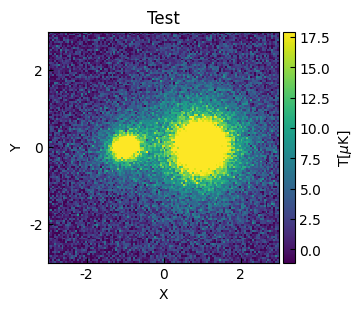

In [4]:
coord = get_coord()
kw_h1 = {
    "amplitude": 60,
    "x_mean": -1,
    "y_mean": 0,
    "fwhm": 0.4,
    "ellipticity":0.2,
    "theta": 0.5
}

nstd = 2
data = gen_test_data(name, *coord, kw_h1=kw_h1, noise_std=nstd)
plot_heatmap(data, title='Test')

In [5]:
model = build_model(name, kw_h1)
print(model)

Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=60., x_mean=-1., y_mean=0., fwhm=0.4, ellipticity=0.2, theta=0.5)>

    [1]: <Lorentz2D(amplitude=50., x_mean=1., y_mean=0., fwhm=1., ellipticity=0., theta=0.)>

    [2]: <Const2D(amplitude=0.)>
Parameters:
    amplitude_0 x_mean_0 y_mean_0 fwhm_0 ... ellipticity_1 theta_1 amplitude_2
    ----------- -------- -------- ------ ... ------------- ------- -----------
           60.0     -1.0      0.0    0.4 ...           0.0     0.0         0.0


# without mask

In [6]:
data_list, fit_info = halofit(coord, data, model=model, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=59.50868621, x_mean=-0.99931534, y_mean=0.00159032, fwhm=0.39969328, ellipticity=0.18349305, theta=0.4523332)>

    [1]: <Lorentz2D(amplitude=50.15766273, x_mean=0.99796534, y_mean=0.00306786, fwhm=1.00031342, ellipticity=0.01346867, theta=-11.14903312)>

    [2]: <Const2D(amplitude=0.01978507)>
Parameters:
       amplitude_0          x_mean_0      ...     amplitude_2    
    ----------------- ------------------- ... -------------------
    59.50868621022868 -0.9993153367237977 ... 0.01978506653783272

Goodness of fit:
Chi-squared: 57745.002
RMS residual: 2.003


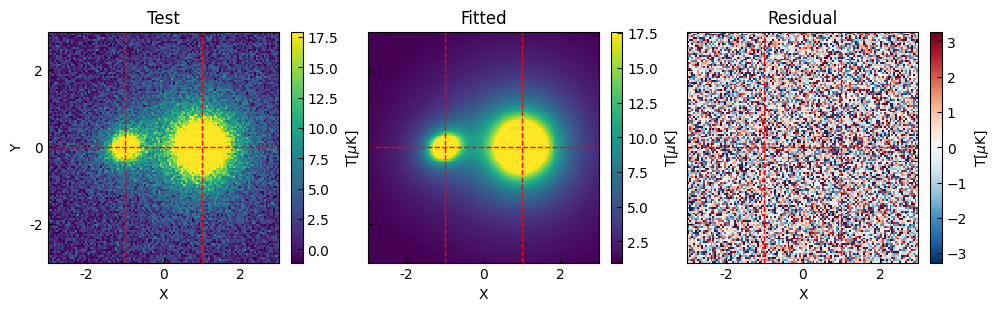

In [7]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list, title=title)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask sector 

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

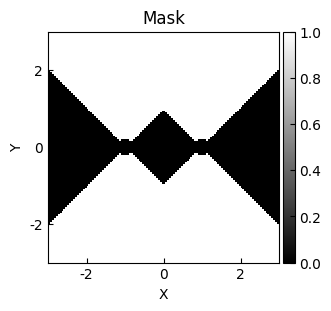

In [8]:
mask = get_mask_sector(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [9]:
data_list_sector, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=60.08244287, x_mean=-0.99166845, y_mean=0.00290342, fwhm=0.40645938, ellipticity=0.20506445, theta=0.40362234)>

    [1]: <Lorentz2D(amplitude=50.3795423, x_mean=1.00386934, y_mean=0.0012465, fwhm=0.9899949, ellipticity=0., theta=-76.02394004)>

    [2]: <Const2D(amplitude=0.04916447)>
Parameters:
       amplitude_0         x_mean_0      ...      theta_1           amplitude_2     
    ----------------- ------------------ ... ------------------ --------------------
    60.08244287384534 -0.991668451475118 ... -76.02394004104502 0.049164470894921916

Goodness of fit:
Chi-squared: 57955.693
RMS residual: 2.006


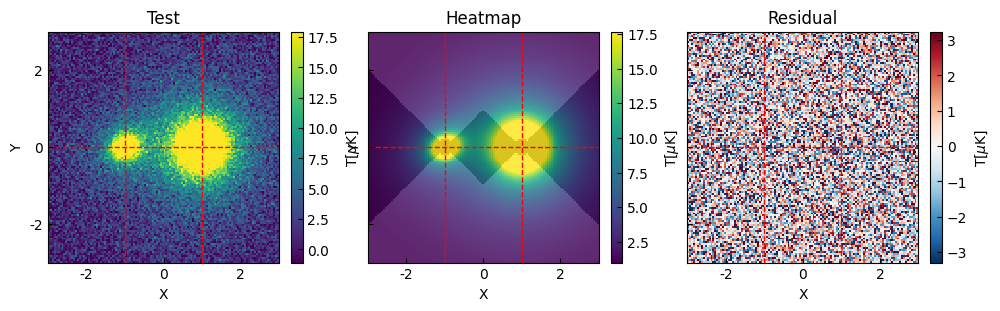

In [10]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_sector, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# with mask square

<Axes: title={'center': 'Mask'}, xlabel='X', ylabel='Y'>

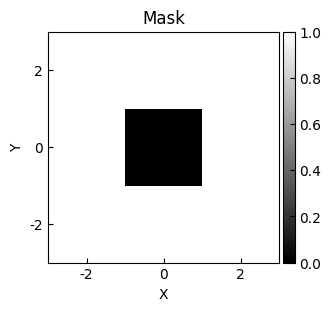

In [11]:
mask = ~get_mask_square(coord=coord)
plot_heatmap(mask, title='Mask', cmap='gray', cbar_label='')

In [12]:
data_list_square, fit_info = halofit(coord, data, model=model, mask=mask, print_model=True)


Fitted double NFW model:
Model: CompoundModel
Inputs: ('x', 'y')
Outputs: ('z',)
Model set size: 1
Expression: [0] + [1] + [2]
Components: 
    [0]: <Lorentz2D(amplitude=60.30636302, x_mean=-0.99624671, y_mean=0.00171748, fwhm=0.39931896, ellipticity=0.18084673, theta=0.44593811)>

    [1]: <Lorentz2D(amplitude=49.61425823, x_mean=1.01213028, y_mean=0.00328309, fwhm=1.00473996, ellipticity=0.03445899, theta=-11.12286226)>

    [2]: <Const2D(amplitude=0.05367035)>
Parameters:
       amplitude_0          x_mean_0      ...     amplitude_2    
    ----------------- ------------------- ... -------------------
    60.30636302247823 -0.9962467144395147 ... 0.05367035435962019

Goodness of fit:
Chi-squared: 58151.533
RMS residual: 2.010


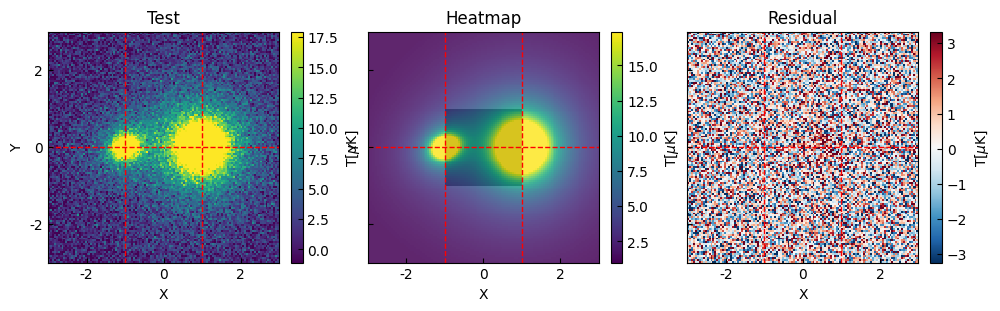

In [13]:
title = ['Test', 'Fitted', 'Residual']
axes =  plot_stack_fit_res(data_list_square, title=title, fit_mask=mask)
plot_axlines(ax=axes, vl=[40, 80], hl=[60])

# compare

In [14]:
from mytools.plot import plot_hist

(-10.0, 10.0)

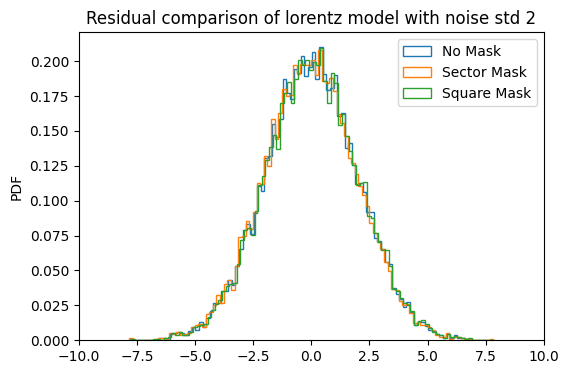

In [15]:
res_list = [data_list[-1].flatten(), data_list_sector[-1].flatten(), data_list_square[-1].flatten()]
labels = ['No Mask', 'Sector Mask', 'Square Mask']
title = 'Residual comparison of %s model with noise std %d' %(name,nstd)
ax = plot_hist(res_list, label=labels, bins=100, title=title)
ax.set_xlim(-10,10)